# 3. Patient samples: a CSV table and an AnnData

A sample query is a whole expression profile on any scale; it is converted to within-sample ranks. Give the rest of
the cohort as the **background** so that the match reflects what is specific to the patient. Tumour-vs-cell-line
differences shared by all samples are then centred away.
- **Table (CSV/TSV):** genes × samples; pick one with `sample=`. The other columns become the background.
- **AnnData:** pick an observation with `sample=`, or pseudobulk a group with `groupby=` / `group=`. Counts are summed and log-CPM normalised; log data are averaged.

The demo data are 45 BeatAML diagnosis bone-marrow samples: 15 KMT2A-r, 15 NPM1-mutant and 15 CBFB-MYH11 (BeatAML 2.0, Bottomly et al. 2022 *Cancer Cell* 40:850–864, doi:10.1016/j.ccell.2022.07.002). They are downloaded the first time with `al.datasets.download("demo")`, which runs automatically below.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import anchorline as al

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20); pd.set_option("display.max_colwidth", 60)
al.settings.figdir = "figures"          # save=True writes here
al.settings.set_figure_params(fontsize=8.5, dpi=150)
atlas = al.load()                       # first time: downloads the atlas (~560 MB) to al.settings.data_dir
atlas

loading atlas from /Users/sina.kanannejad/.anchorline/data (~1-2 min, ~1.5 GB RAM)
  8894 reference samples (2805 untreated), 42003 genes; 1608 drug-vs-control contrasts


anchorline Atlas (/Users/sina.kanannejad/.anchorline/data)
  reference: 8894 samples (2805 untreated) x 42003 genes
  contrasts: 1608 (226 studies, 63 models, 363 drugs)

In [2]:
D = al.datasets.demo_path().parent          # downloads the demo set the first time
samples = pd.read_csv(D / "beataml_demo_samples.csv", index_col=0)
samples.group.value_counts()

group
KMT2A-r       15
NPM1-mut      15
CBFB-MYH11    15
Name: count, dtype: int64

## A sample from a CSV table

In [3]:
sid = samples.index[samples.group == "KMT2A-r"][0]
print(sid, samples.loc[sid, "fusion"])
mt = al.tl.match(atlas, D / "beataml_demo_expression.csv", sample=sid)
mt

BA2031R KMT2A_re


MatchResult 'BA2031R' (sample, models=cell_lines): 31 models ranked
  top: MOLM-14 (0.14), MOLM-13 (0.11), MV4-11 (0.11), OCI-AML3 (0.08), EOL-1 (0.08)
  .table .groups .samples .top(n) .select(...)

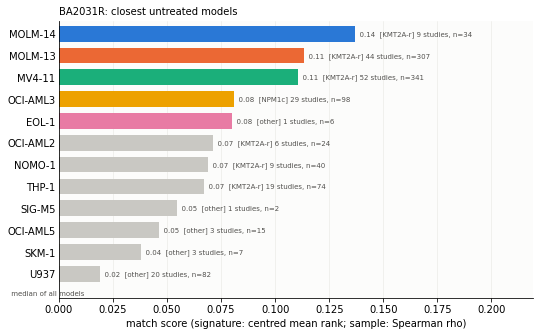

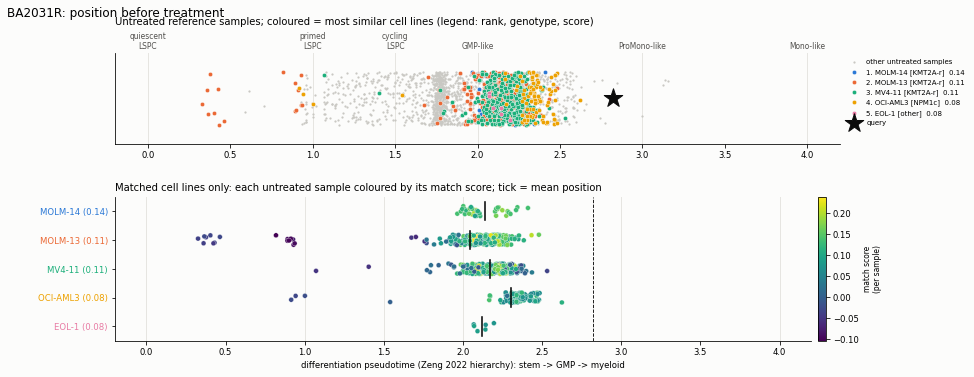

In [4]:
al.pl.match_ranking(mt, n_top=12)
al.pl.pseudotime(mt, n_top=5)            # the star = this patient's position

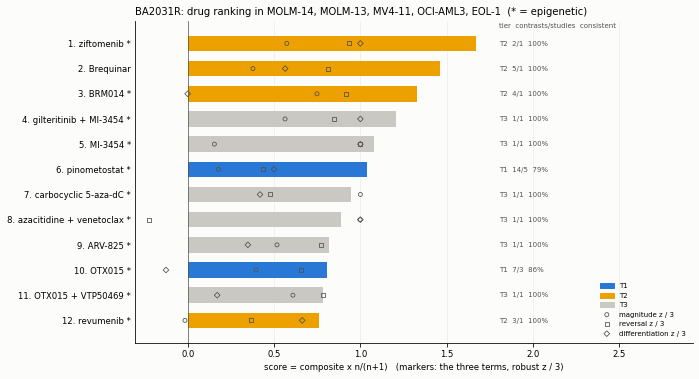

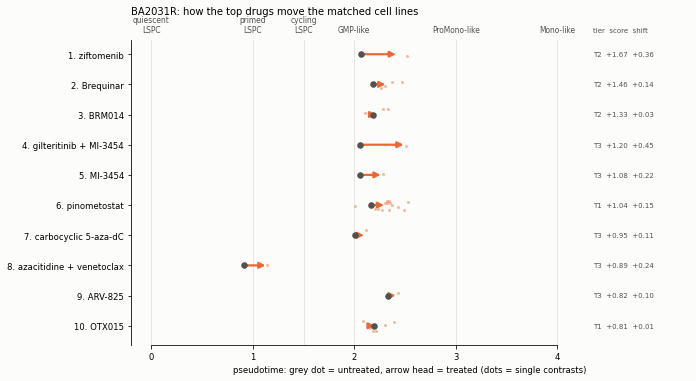

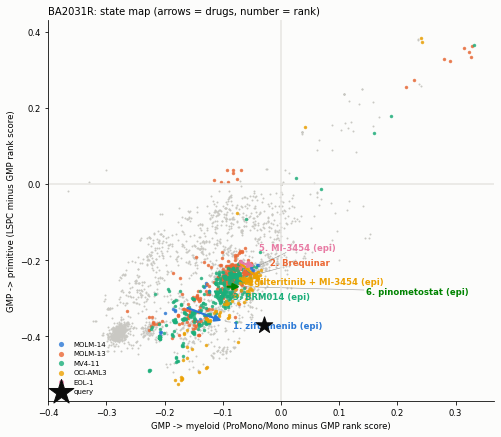

In [5]:
dr = al.tl.rank_drugs(atlas, mt, cell_lines=5)
al.pl.drug_ranking(dr, n_top=12)
al.pl.drug_shifts(dr, n_top=10)
al.pl.state_map(dr, n_top=6)

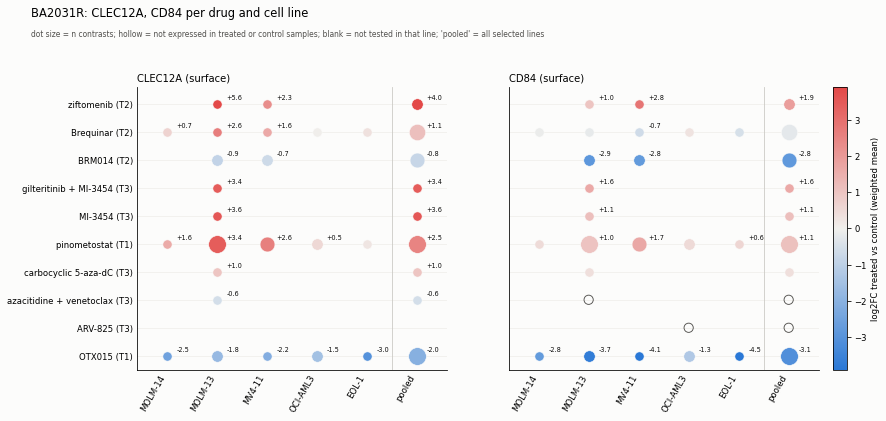

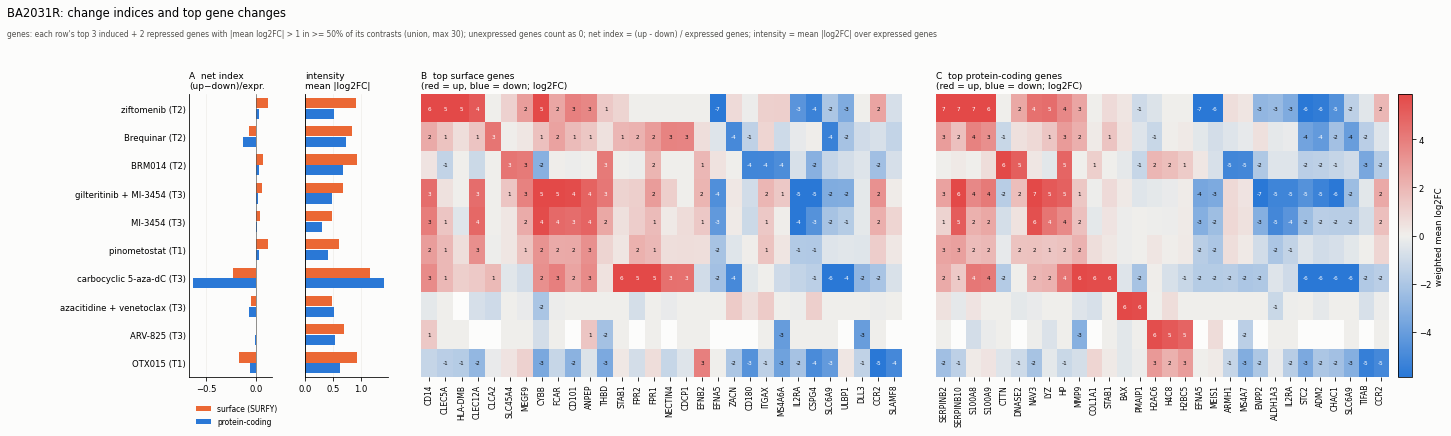

In [6]:
al.pl.gene_changes(dr, genes=["CLEC12A", "CD84"], n_top=10)
al.pl.top_gene_changes(dr, n_top=10)

For a sample query, `signature_changes` uses the patient's own most specific genes: the 100 most above and 100 most below its cohort, capped for display.

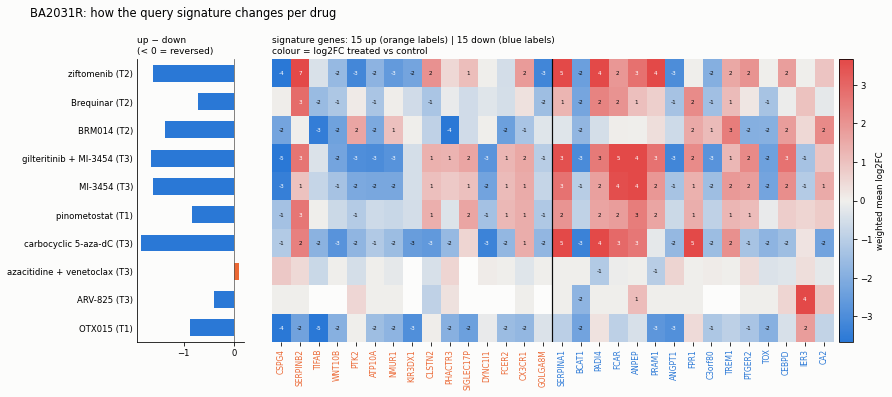

In [7]:
al.pl.signature_changes(dr, n_top=10, max_genes=30)

## The same data as an AnnData

In [8]:
adata = al.datasets.beataml_demo()
adata

AnnData object with n_obs × n_vars = 45 × 22843
    obs: 'group', 'fusion', 'NPM1', 'FLT3_ITD', 'ELN2017', 'age'
    uns: 'source'

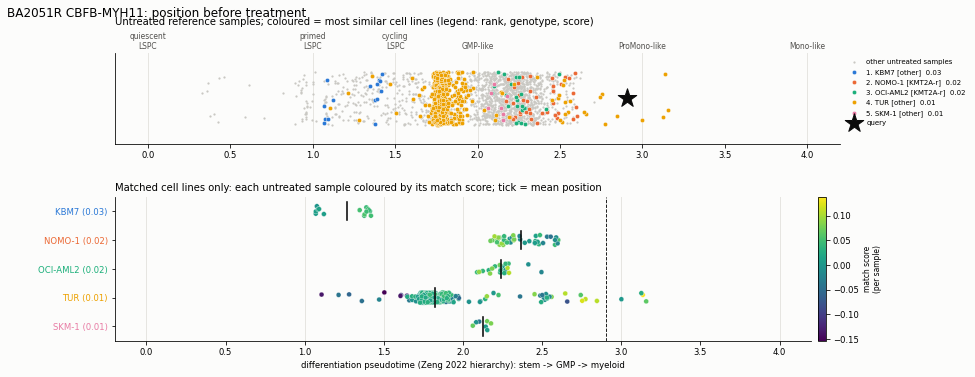

In [9]:
# one observation; the other observations are the background
sid2 = samples.index[samples.group == "CBFB-MYH11"][0]
mt_cbf = al.tl.match(atlas, adata, sample=sid2, name=f"{sid2} CBFB-MYH11")
al.pl.pseudotime(mt_cbf, n_top=5)

**Pseudobulk per group** works the same way for single-cell data, e.g. `groupby="leiden"` / `group="3"`.

Here each genotype group is pooled, and the other two groups act as the background. With only three groups that background is small: for real single-cell data, use many clusters or samples.

In [10]:
res = {}
for g in ["KMT2A-r", "NPM1-mut", "CBFB-MYH11"]:
    m = al.tl.match(atlas, adata, groupby="group", group=g, name=f"BeatAML {g} (pseudobulk)")
    res[g] = (m, al.tl.rank_drugs(atlas, m, cell_lines=5))
    print(g, "->", ", ".join(f"{c} [{t}]" for c, t in m.table.genotype.head(5).items()))

KMT2A-r -> MOLM-13 [KMT2A-r], MOLM-14 [KMT2A-r], NOMO-1 [KMT2A-r], OCI-AML2 [KMT2A-r], MV4-11 [KMT2A-r]
NPM1-mut -> SET2 [other], TF-1 [other], CMK [other], HEL [other], IMS-M2 [NPM1c]
CBFB-MYH11 -> HNT-34 [other], SKNO-1 [other], ML-2 [KMT2A-r], KG-1a [other], IMS-M2 [NPM1c]


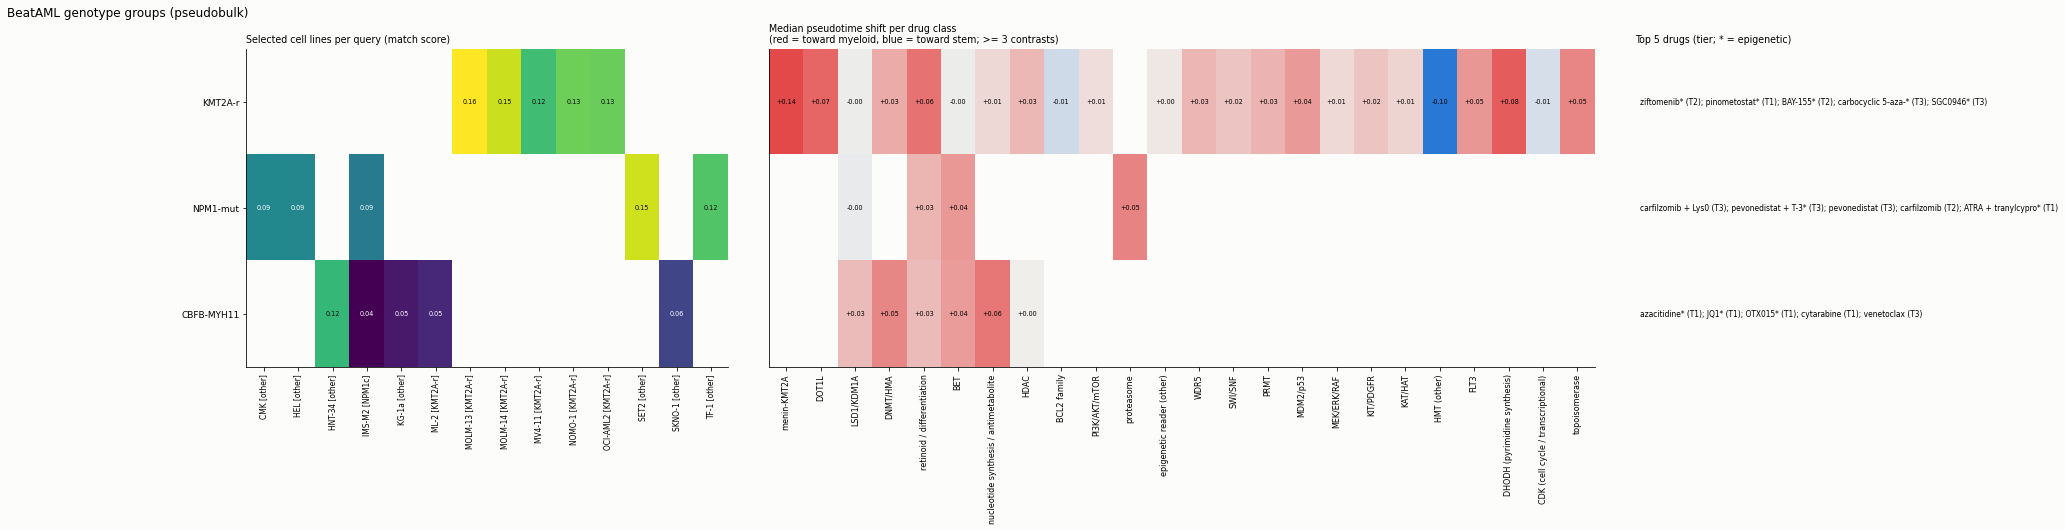

In [11]:
al.pl.group_summary(res, title="BeatAML genotype groups (pseudobulk)")

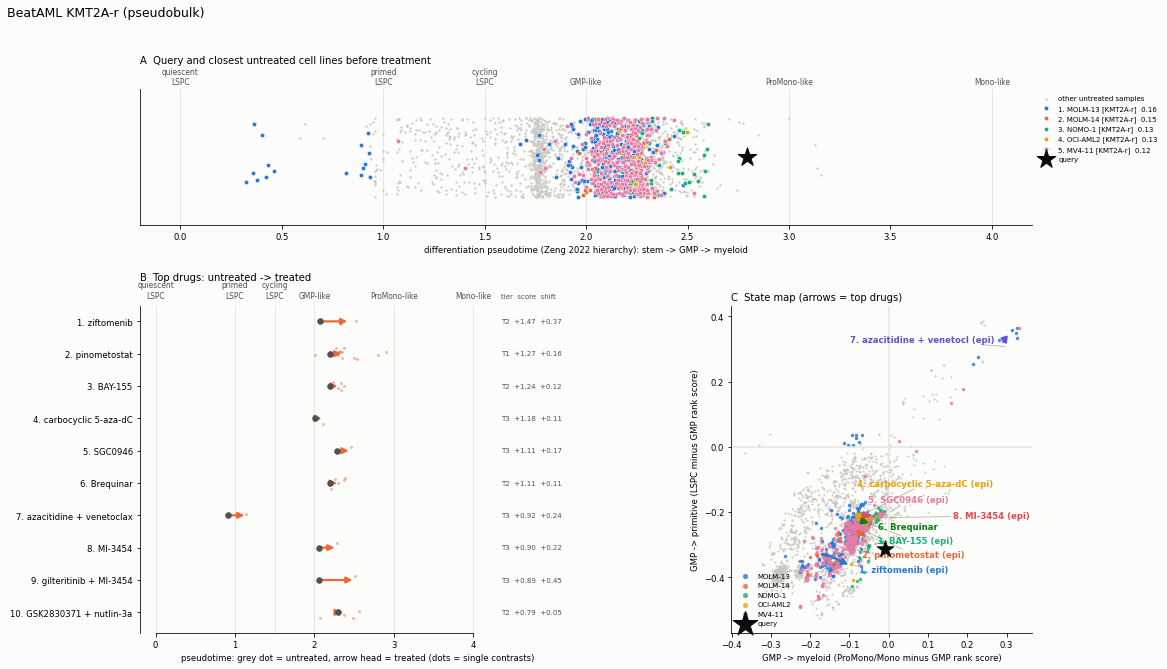

classes with < 2 contrasts in the selected cell lines: ['BCL2']


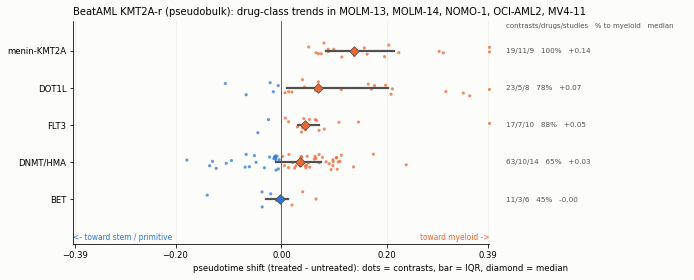

In [12]:
m, d = res["KMT2A-r"]
al.pl.summary(m, d, n_top=10)
al.pl.class_trends(d, classes=["menin-KMT2A", "DOT1L", "BET", "FLT3", "BCL2", "DNMT/HMA"])